# Predicting Sales Prices

 ## Dataset Attributes

 The dataset contains information about houses in Ames, Iowa. The data was collected by the Ames City Assessor’s Office describing 2930 property sales which occurred in Ames, Iowa between 2006 and 2010. The dataset, containing 81 variables, was compiled and published by De Cock in 2011.

 Some of the variables contained in the original dataset have been removed from the the dataset provided to you.
 The dataset provided to you contains the following variables:
* **Year_Built:** year that the house was originally constructed
* **Year_Remod_Add:** year that the house was last remodelled
* **Total_Bsmt_SF:** total size of basement area in square feet
* **First_Flr_SF:** size of the first floor in square feet
* **Second_Flr_SF:** size of the second floor in square feet
* **Gr_Liv_Area:** size of above grade, ground living area in square feet
* **Full_Bath:** number of full above grade bathrooms in the house
* **Half_Bath:** number of half above grade bathrooms in the house
* **Bedroom_AbvGr:** number of above grade bedrooms (does not include basement bedrooms)
* **Kitchen_AbvGr:** number of above grade kitchens
* **TotRms_AbvGrd:** total number of above grade rooms (does not include bathrooms)
* **Fireplaces:** number of fireplaces in the house
* **Garage_Area:** size of garage in square feet
* **Sale_Price:** sale price of the house in dollars


*De Cock, D. (2011). "Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester
Regression Project," Journal of Statistics Education, Volume 19, Number 3.*

- https://ww2.amstat.org/publications/jse/v19n3/decock/DataDocumentation.txt
- http://ww2.amstat.org/publications/jse/v19n3/decock.pdf


 ## Objective

 The goal of this task is to analyse the relationship between these variables and build a multiple linear regression model to predict the sales prices based on the 'Gr_Liv_Area' and 'Garage_Area` variables.


In [1]:
# Import libraries
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
# Read in the data set
df = pd.read_csv("ames.csv")
print(df.shape)
df.head()

(2930, 14)


,Year_Built,Year_Remod_Add,Total_Bsmt_SF,First_Flr_SF,Second_Flr_SF,Gr_Liv_Area,Full_Bath,Half_Bath,Bedroom_AbvGr,Kitchen_AbvGr,TotRms_AbvGrd,Fireplaces,Garage_Area,Sale_Price
0,1960,1960,1080,1656,0,1656,1,0,3,1,7,2,528,215000
1,1961,1961,882,896,0,896,1,0,2,1,5,0,730,105000
2,1958,1958,1329,1329,0,1329,1,1,3,1,6,0,312,172000
3,1968,1968,2110,2110,0,2110,2,1,3,1,8,2,522,244000
4,1997,1998,928,928,701,1629,2,1,3,1,6,1,482,189900


In [3]:
# Clean and pre-process the data if neccessary
# 1. Check missing values
print(df.isna().sum())

# 2. Check data types
print(df.info())

# 3. Check numerical statistics/outliers
print(df.describe())

#4. Columns in ames data - for the next task
print(df.columns)

Year_Built        0
Year_Remod_Add    0
Total_Bsmt_SF     0
First_Flr_SF      0
Second_Flr_SF     0
Gr_Liv_Area       0
Full_Bath         0
Half_Bath         0
Bedroom_AbvGr     0
Kitchen_AbvGr     0
TotRms_AbvGrd     0
Fireplaces        0
Garage_Area       0
Sale_Price        0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Year_Built      2930 non-null   int64
 1   Year_Remod_Add  2930 non-null   int64
 2   Total_Bsmt_SF   2930 non-null   int64
 3   First_Flr_SF    2930 non-null   int64
 4   Second_Flr_SF   2930 non-null   int64
 5   Gr_Liv_Area     2930 non-null   int64
 6   Full_Bath       2930 non-null   int64
 7   Half_Bath       2930 non-null   int64
 8   Bedroom_AbvGr   2930 non-null   int64
 9   Kitchen_AbvGr   2930 non-null   int64
 10  TotRms_AbvGrd   2930 non-null   int64
 11  Fireplaces      2930 non-null   int6

Correlation matrix is : 
                Year_Built  Year_Remod_Add  Total_Bsmt_SF  First_Flr_SF  \
Year_Built            1.00            0.61           0.41          0.31   
Year_Remod_Add        0.61            1.00           0.30          0.24   
Total_Bsmt_SF         0.41            0.30           1.00          0.80   
First_Flr_SF          0.31            0.24           0.80          1.00   
Second_Flr_SF         0.02            0.16          -0.20         -0.25   
Gr_Liv_Area           0.24            0.32           0.45          0.56   
Full_Bath             0.47            0.46           0.33          0.37   
Half_Bath             0.27            0.21          -0.05         -0.10   
Bedroom_AbvGr        -0.06           -0.02           0.05          0.11   
Kitchen_AbvGr        -0.14           -0.14          -0.04          0.08   
TotRms_AbvGrd         0.11            0.20           0.28          0.39   
Fireplaces            0.17            0.13           0.33          0.41   


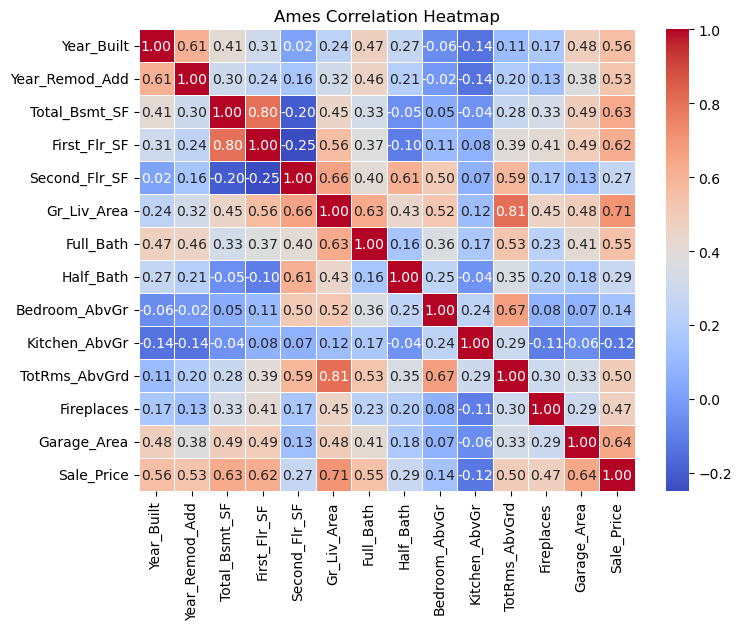

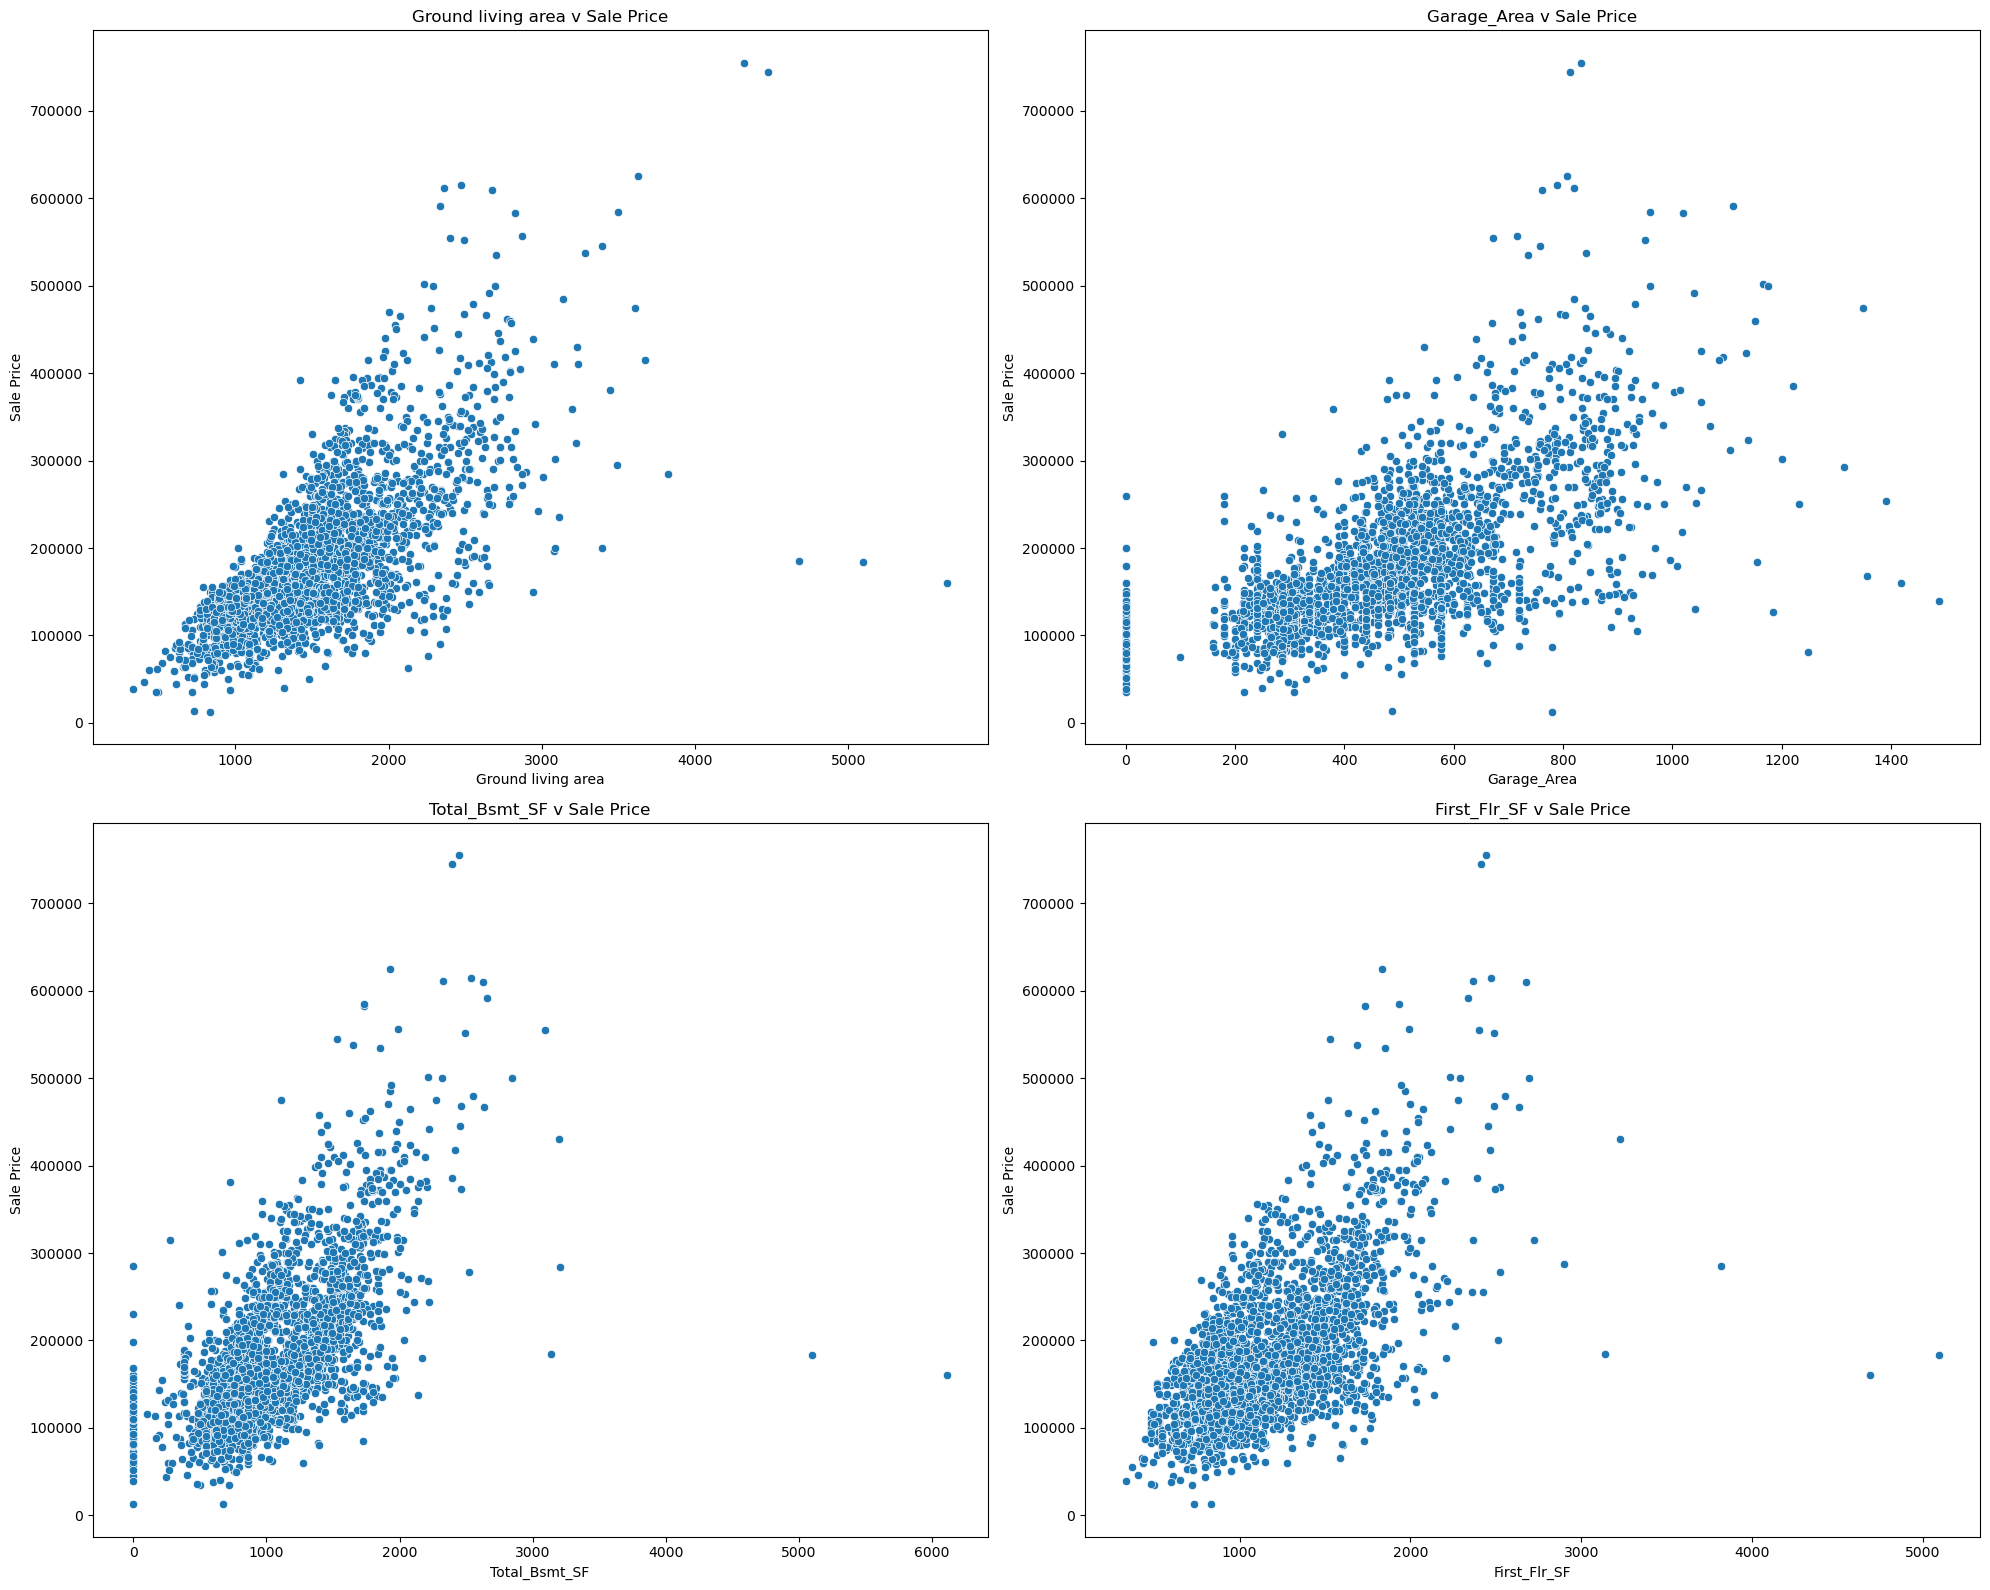

In [4]:
# Explore the data with visualisations such as histograms and correlation matrices

matrix = df.corr()
print("Correlation matrix is : ")
print(round(matrix,2))

# Plot 1: Ames Correlation Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Ames Correlation Heatmap")
plt.show()

# Create a figure with 3 rows and 2 columns of subplots
# figsize controls the size of the complete figure
fig, ax = plt.subplots(2, 2, figsize=(20, 16))

### The graphs below are from the top 4 correlated columns with Sales Price

# Plot 2: Ground living area v Sale Price
sns.scatterplot(data=df, x='Gr_Liv_Area', y ='Sale_Price', ax=ax[0, 0])
ax[0, 0].set_title("Ground living area v Sale Price")
ax[0, 0].set_xlabel("Ground living area")
ax[0, 0].set_ylabel("Sale Price")

# Plot 3: Garage_Area v Sale Price
sns.scatterplot(data=df, x='Garage_Area', y ='Sale_Price', ax=ax[0, 1])
ax[0, 1].set_title("Garage_Area v Sale Price")
ax[0, 1].set_xlabel("Garage_Area")
ax[0, 1].set_ylabel("Sale Price")

# Plot 4: Total_Bsmt_SF v Sale Price
sns.scatterplot(data=df, x='Total_Bsmt_SF', y ='Sale_Price', ax=ax[1, 0])
ax[1, 0].set_title("Total_Bsmt_SF v Sale Price")
ax[1, 0].set_xlabel("Total_Bsmt_SF")
ax[1, 0].set_ylabel("Sale Price")

# Plot 5: First_Flr_SF v Sale Price
sns.scatterplot(data=df, x='First_Flr_SF', y ='Sale_Price', ax=ax[1, 1])
ax[1, 1].set_title("First_Flr_SF v Sale Price")
ax[1, 1].set_xlabel("First_Flr_SF")
ax[1, 1].set_ylabel("Sale Price")

# Adjust plot
plt.tight_layout()

# Display all plots
plt.show()

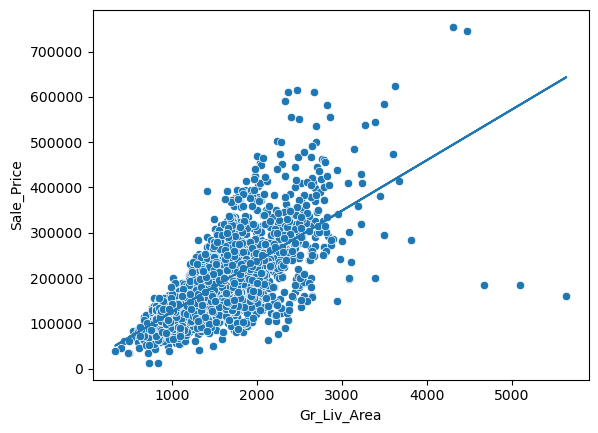

In [5]:
# Split the independent variables from the dependent variable
A = df['Gr_Liv_Area'].values.reshape(-1,1)
b = df['Sale_Price']
Ground_liv_area_model = LinearRegression()
Ground_liv_area_model.fit(A,b)

# Plot the scatter plot of the original data 
sns.scatterplot(data=df, x='Gr_Liv_Area', y='Sale_Price',) 
y_pred1 = Ground_liv_area_model.predict(A)
# Plot the linear regression line based on the predictions 
plt.plot(A, y_pred1) 

# Display and close the plot 
plt.show() 
plt.close()

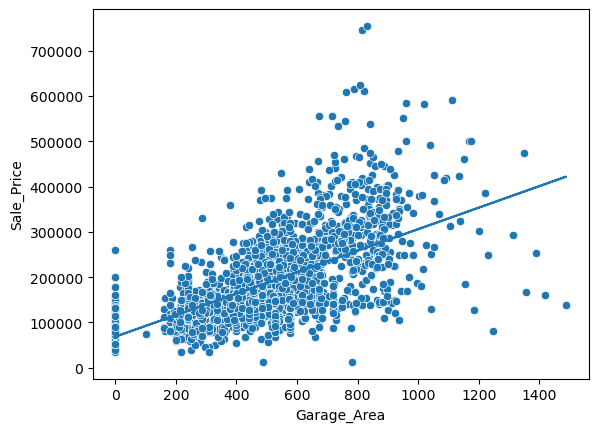

In [6]:
# Split the independent variables from the dependent variable
C = df['Garage_Area'].values.reshape(-1,1)
d = df['Sale_Price']
Garage_Area_model = LinearRegression()
Garage_Area_model.fit(C,d)

# Plot the scatter plot of the original data 
sns.scatterplot(data=df, x='Garage_Area', y='Sale_Price') 
y_pred2 = Garage_Area_model.predict(C)
# Plot the linear regression line based on the predictions 
plt.plot(C, y_pred2) 

# Display and close the plot 
plt.show() 
plt.close()

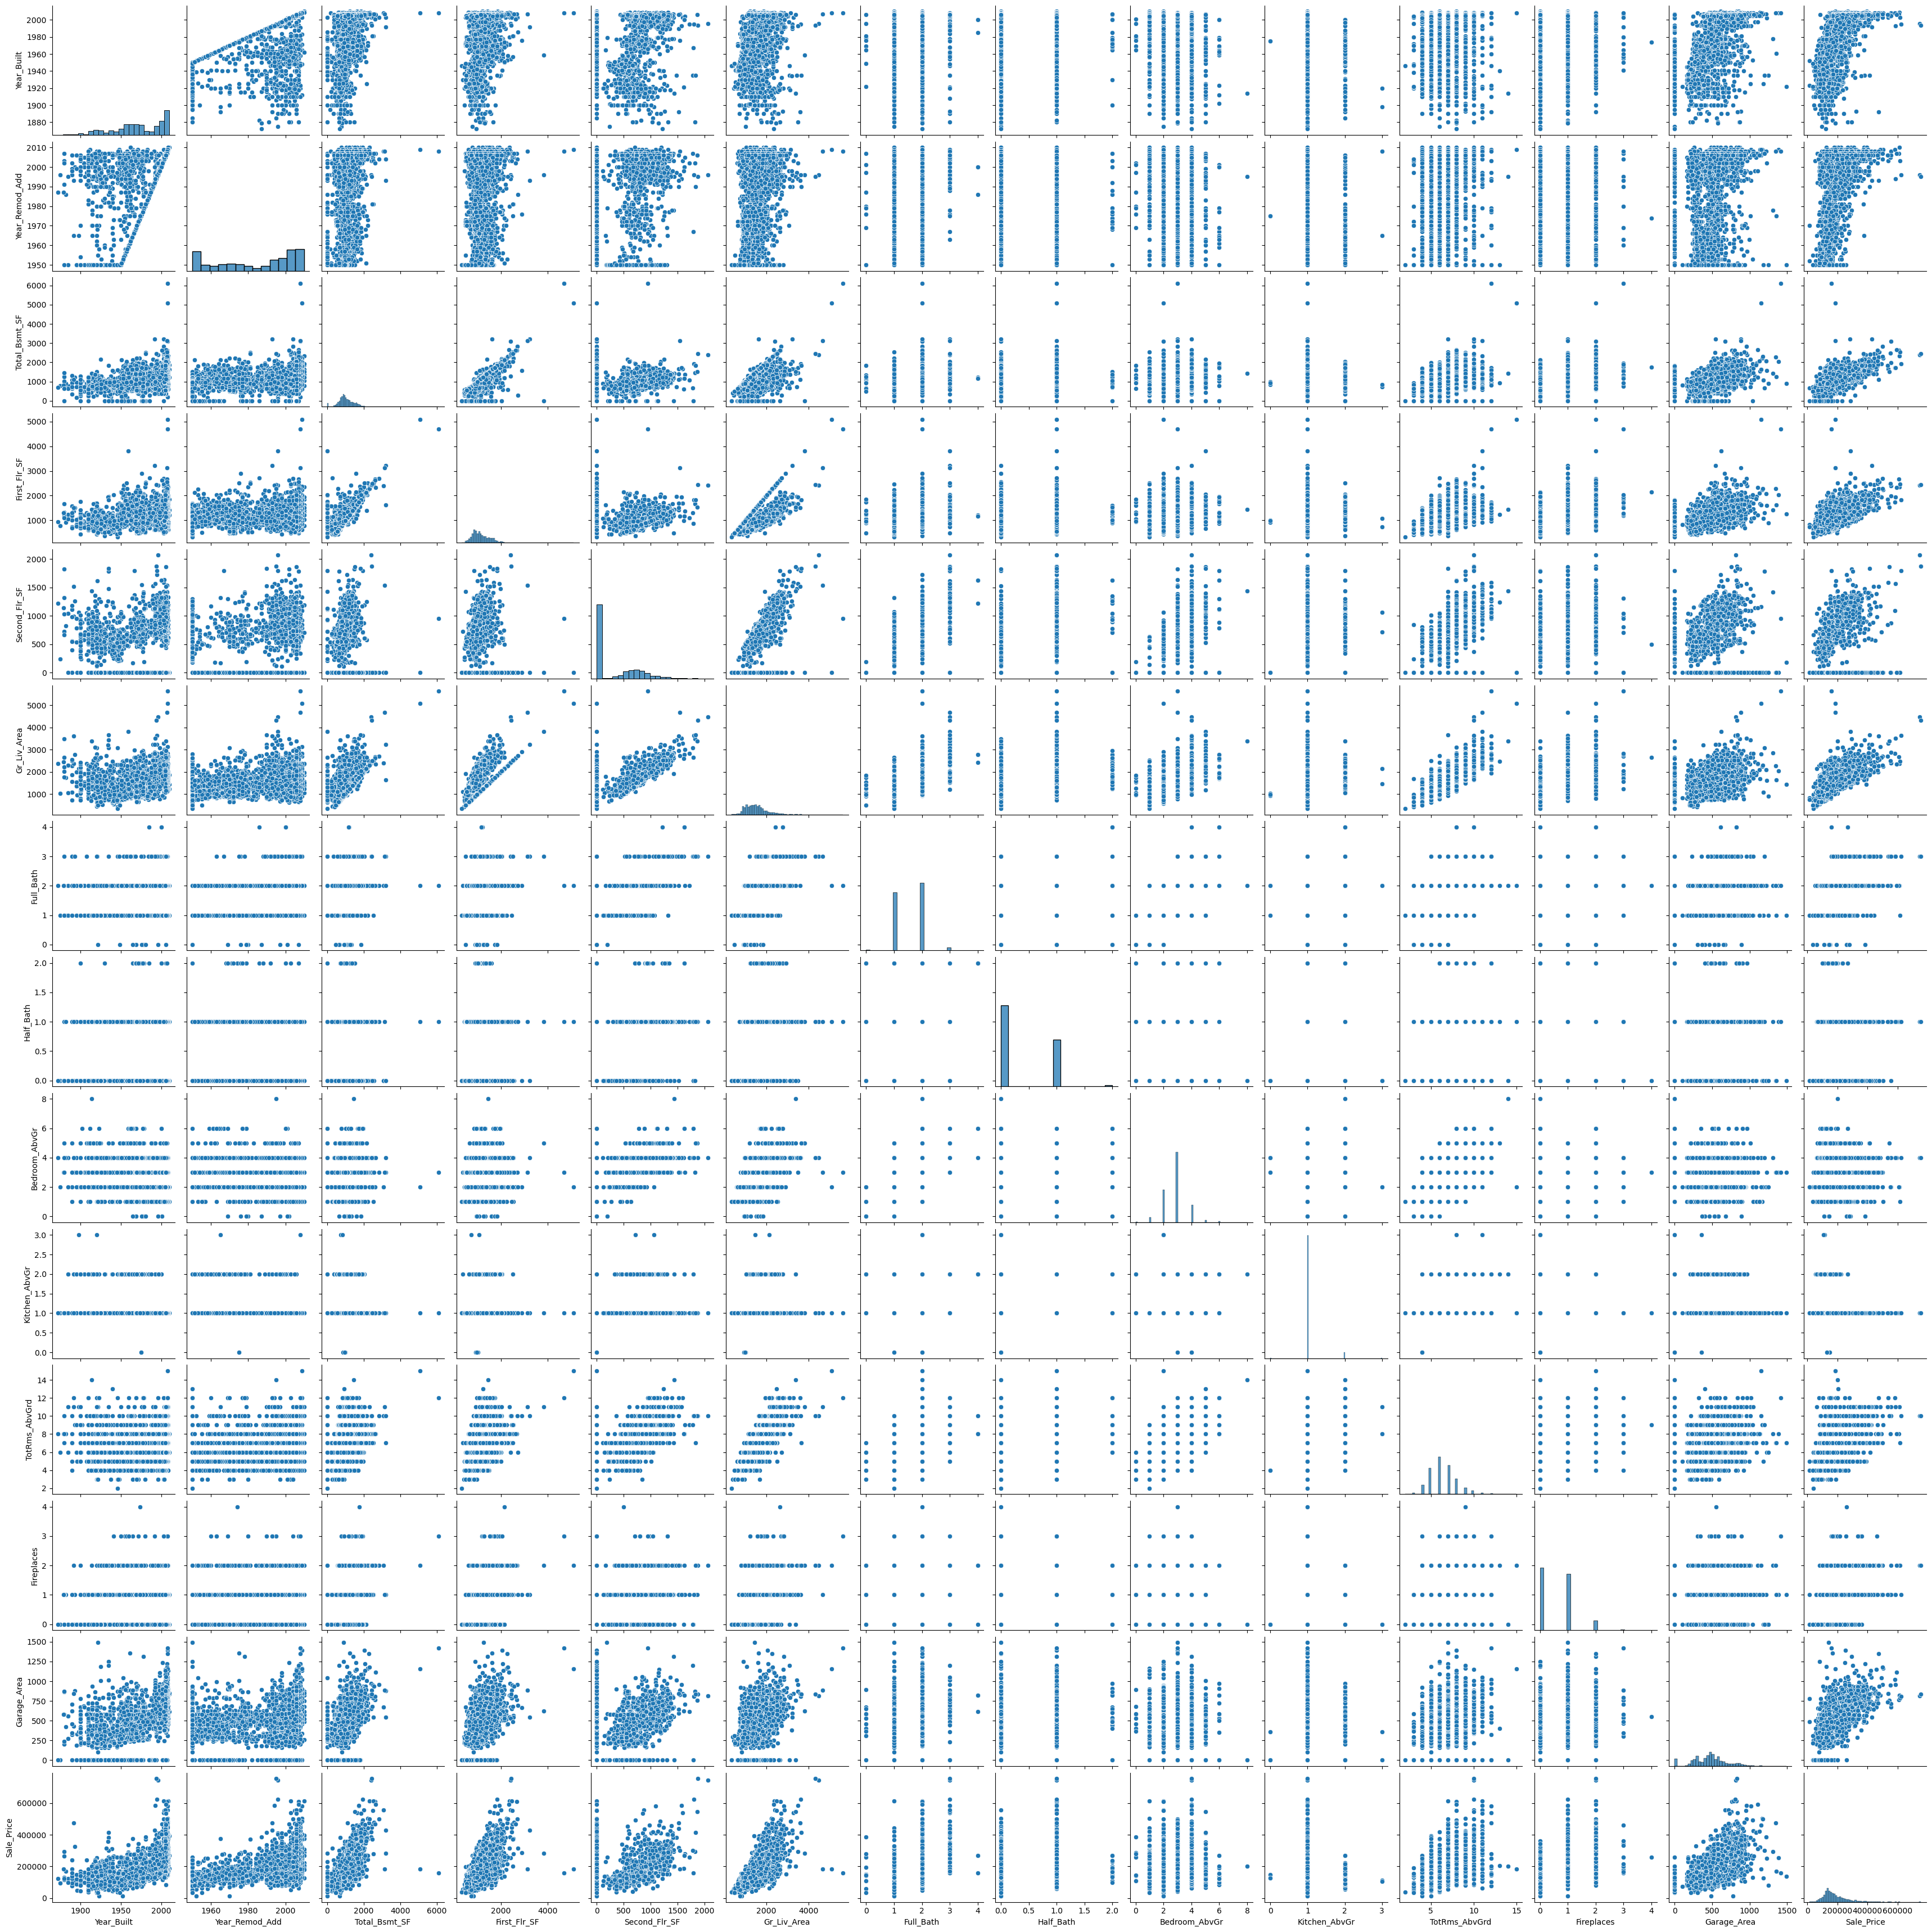

In [7]:
# Generate plots to explore the relationships between the independent and dependent variables
# Plot the distribution of the data
sns.pairplot(data=df)

In [8]:
# Model for Garage and ground living area
X = df.iloc[:,[5,12]].values
y = df.iloc[:,13].values
y = y.reshape(-1, 1)

Sale_Price_model = LinearRegression()
Sale_Price_model.fit(X,y)

print('Intercept: \n', Sale_Price_model.intercept_)
print('Coefficient: \n', Sale_Price_model.coef_)

Intercept: 
 [-10365.25158597]
Coefficient: 
 [[ 81.92294905 144.50658946]]


In [9]:
# Create a training and test set with a 75:25 split ratio
r_seed = 42
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.25, random_state= r_seed)

print("Training data:",X_train.shape, y_train.shape)
print("Test data:",X_test.shape, y_test.shape)

Training data: (2197, 2) (2197, 1)
Test data: (733, 2) (733, 1)


In [10]:
# Build a multiple linear regression model using 'Gr_Liv_Area' and 'Garage_Area'
# Fit the scaler on train data
sc = StandardScaler()
sc.fit(X_train)

# Apply the scaler on train and test data
X_train = sc.transform(X_train)
X_test = sc.transform(X_test)

# Fit a model
lm = LinearRegression()
model = lm.fit(X_train, y_train)
predictions = lm.predict(X_test)

In [11]:
# Print the trained model's intercept and coefficients
print('Intercept: \n', lm.intercept_)
print('Coefficients: \n', lm.coef_)

Intercept: 
 [179066.78197542]
Coefficients: 
 [[40156.97174031 30009.56807696]]


In [12]:
# Generate predictions for the test set
print(predictions)

[[158224.09430889]
 [113256.67578876]
 [217552.81911301]
 [ 72846.49160079]
 [ 94782.71287234]
 [159556.51682943]
 [147050.44791809]
 [171621.4840609 ]
 [ 81392.38908909]
 [283579.83964666]
 [249100.05496851]
 [168499.92432513]
 [116583.03074089]
 [212221.76188258]
 [187920.93674966]
 [163726.89707186]
 [143432.22833369]
 [193274.44510564]
 [147212.84811163]
 [145632.7796358 ]
 [195865.83959285]
 [163271.54952544]
 [203828.00781662]
 [201602.15637358]
 [190404.12127406]
 [290163.54380853]
 [270024.1527255 ]
 [200336.51758461]
 [224841.39700036]
 [185508.69555082]
 [192828.44289823]
 [ 98840.951416  ]
 [196403.1847392 ]
 [166079.07872082]
 [211130.7176415 ]
 [121240.83942198]
 [158938.19944435]
 [250562.16978582]
 [236607.60491921]
 [176033.29915242]
 [317789.64117299]
 [231310.79402225]
 [236415.57370233]
 [193461.91758205]
 [ 77804.14231511]
 [298080.24013606]
 [177323.55450817]
 [188141.74412733]
 [174760.36653663]
 [161487.08497971]
 [200410.42385456]
 [108137.93545956]
 [134322.602

In [23]:
# Evaluate the model's performance by computing the mean squared error (MSE) or root mean squared error (RMSE) on the test set using sklearn.metrics.
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, predictions)
print(f"MSE: {mse}")


from sklearn.metrics import root_mean_squared_error

rmse = root_mean_squared_error(y_test, predictions)
print(f"RMSE: {rmse}")

# This is done additionally to help understand how much of the target value - Sale Price the 2 variables Gr_Liv_Area and Garage_Area explain as a model.
from sklearn.metrics import r2_score
r2 = r2_score(y_test, predictions)

# Print the R² score
print(f"R² score: {r2}")

MSE: 2634371879.6902113
RMSE: 51326.132522236774
R² score: 0.6386357969815797


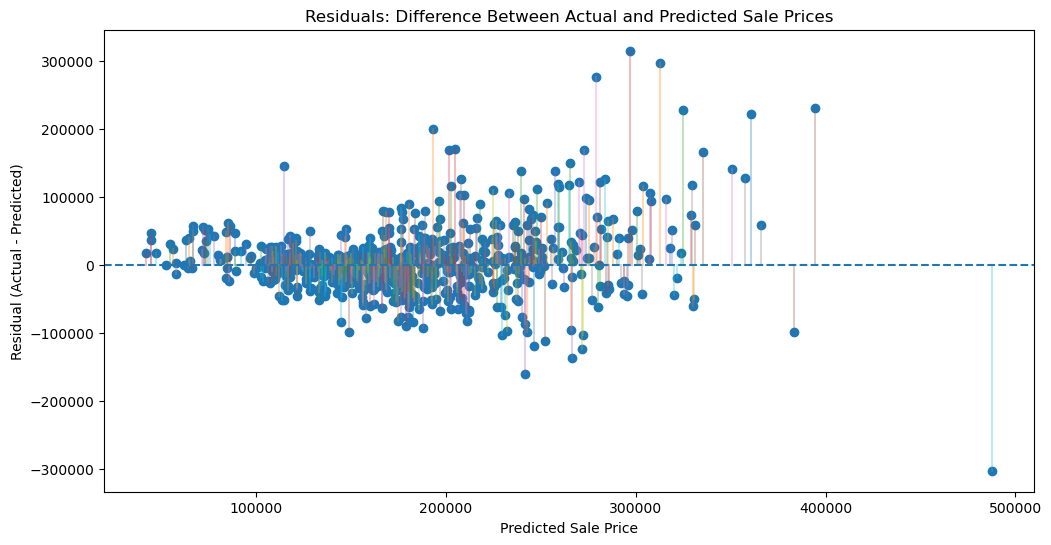

In [22]:
# Generate an error plot to visualise the differences between the predicted and actual values in the test set.
# Calculate residuals
errors = y_test.ravel() - predictions.ravel()

# Create the residual plot
plt.figure(figsize=(12, 6))

plt.scatter(predictions.ravel(), errors)

# Draw a line from zero to each residual
for x, error in zip(predictions.ravel(), errors):
    plt.plot([x, x], [0, error], alpha=0.3)

# Zero-error line
plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Sale Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals: Difference Between Actual and Predicted Sale Prices")

plt.show()

In [18]:
# Print the coefficients and interpret them within the context of the median value prediction.
median_value =  lm.intercept_ + lm.coef_[0,0]*X_test[0,0] + lm.coef_[0,1]*X_test[0,1]
print(median_value)

[158224.09430889]


**Interpret coefficients in the context of the prediction:**

(all prices are in dollars.)

The model has an intercept of approximately 179,066.78. This represents the predicted sale price when the scaled values of the independent variables are zero.

The coefficient for Gr_Liv_Area is approximately 40,156.97. This indicates that Gr_Liv_Area has a positive relationship with Sale Price. When the standardised value of Gr_Liv_Area increases by one unit, the predicted sale price increases by approximately $40,156.97, while keeping Garage_Area constant.

The coefficient for Garage_Area is approximately 30,009.57. This also indicates a positive relationship with Sale Price. When the standardised value of Garage_Area increases by one unit, the predicted sale price increases by approximately 30,009.57, while keeping Gr_Liv_Area constant.

Overall, both variables have positive coefficients, meaning that larger living areas and larger garage areas are associated with higher predicted house sale prices in this model.

**Summarise findings**
(all prices are in dollars except MSE as it is squared.)

The exploratory data analysis showed relationships between house sale price and several of the numerical variables in the dataset. In particular, `Gr_Liv_Area` and `Garage_Area` showed positive relationships with `Sale_Price`. The correlation analysis provided evidence that these variables could be the most useful predictors of house prices with correlation of 0.71 or 71% and 0.64 or 64%. 

A multiple linear regression model was created using `Gr_Liv_Area` and `Garage_Area` as the independent variables. The data was divided into training and test sets using a 75:25 split, and the trained model was then used to make predictions for the test data.

The model produced an MSE of approximately 2,634,371,879.69 and an RMSE of approximately 51,326.13. This means that the typical size of the prediction error, represented by the RMSE, was around 51,326.

The model coefficients for both `Gr_Liv_Area` and `Garage_Area` were positive, indicating that increases in these variables were associated with higher predicted sale prices in the model.
The error plot also showed differences between the actual and predicted sale prices. This indicates that although the two variables provide useful information for predicting house prices, they do not explain all of the variation in sale prices. 

Other characteristics of houses may also contribute to differences in their sale prices. An R² of approximately 0.638 means that the model explains about 63.8% of the variation in the target values on the test data.